# State of the art: the supervisory stress-test models, vine copulas, growth-at-risk and Bayesian VARs

**Question:** Next to the published practice for aggregating risks and measuring model risk, how much does one capital figure of
Banco Andino hide, and how far could the reference model be wrong before its capital changes?

- **Level:** 3, State of the art
- **Prerequisites:** notebooks 01 to 03 of this topic (the aggregation, the band and its bounds)
- **Reading time:** about 60 minutes

## Objectives

By the end of this notebook you can:

- simulate the Gaussian aggregate of Banco Andino's four risks and read its capital, the one figure that the published
  measures of model risk will question;
- read the published practice around supervisory stress-test models, scenario generators, risk aggregation and model risk, and
  say what the case implements and what it leaves out;
- run the Barrieu and Scandolo add-on multiplier and relative measure over the eight models of the band, and read what they say
  about the spread among the models;
- run the Glasserman and Xu worst case within an entropy budget on the simulated aggregate, and say how fast it grows;
- compare the case with the published practice on the numbers that can be measured on the committed documents.

## Setup

Install the pinned notebook environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or install only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds the whole environment, `.venv-notebooks`, for you. A notebook never installs anything by itself. 
The next cell imports what the notebook uses and prints the versions of the packages, so that you can compare them with the pins.

In [1]:
# Imports, versions and the reader of the committed documents (three folders below the repository root)
import importlib.metadata as md
import json
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.aggregation import copulas as cop
from riskvalidation.aggregation import model_risk
from riskvalidation.portfolio import portfolio as rv_port
from riskvalidation.validation import aggregation as agg_tests

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))
DERIVED = Path("../../..").resolve() / "data" / "derived"


def read_json(relative):
    return json.loads((DERIVED / relative).read_text(encoding="utf-8"))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

This notebook reads the aggregation block of **C18** (Banco Andino), as notebooks 01 to 03 do.

- **Owner and licence:** the documents are written by this repository's offline pipeline (`data-pipeline/pipeline/cases/c18/`) with the engine `riskvalidation` and committed under `data/derived/C18/`. The scenario paths come from the Federal Reserve (public domain), the EBA and ESRB (reproduction authorised with the source acknowledged) and the NGFS (derived-only: only the few variables the case uses). **Banco Andino is a synthetic bank**: its book and capital are calibrated to public aggregates, and the scenario paths are real United States and euro-area paths transposed onto its jump-off, so the satellites are a US-calibrated adaptation.
- **Truth status:** `synthetic-calibrated`. There is no answer key for the bank; the checks of this notebook are recomputations of committed numbers with the engine, not comparisons with a published result.
- **Baked by:** `riskvalidation` 1.0.1 (seed 42), the version this notebook installs, so a recomputation is expected to match to rounding.
- **Files read:** `data/derived/C18/baseline.json` (`outputs.aggregation`: marginals, band, correlation matrix, and the committed `model_risk` block with the Barrieu-Scandolo and Glasserman-Xu results; and `outputs.backcast` for the satellites' out-of-time fit), `data/derived/C18/t-copula-baseline.json` (the Rosenberg and Schuermann reference) and `data/derived/C18/models-banco-andino.json` (`fit.aggregation.quantile_grid`).
- **The marginals are rebuilt from the committed quantile grids, for one step.** The Glasserman-Xu measure needs the simulated losses of the aggregate, which the document does not hold, so step 2 rebuilds the marginals of notebook 02 from the grids and simulates the Gaussian aggregate with the case's seed; the committed numbers are printed beside it.

In [2]:
# The aggregation block of the baseline, the correlation matrix, the band and the committed quantile grids
baseline_doc = read_json("C18/baseline.json")
agg = baseline_doc["outputs"]["aggregation"]
grid = read_json("C18/models-banco-andino.json")["fit"]["aggregation"]["quantile_grid"]
R = np.array(agg["correlation"]["matrix"])
band = agg["band"]
marginals = agg["marginals"]
NAMES = {"lower-bound": "lower bound", "simple-sum": "simple sum",
         "variance-covariance": "variance-covariance", "gaussian-copula": "Gaussian copula (reference)",
         "t-copula": "t copula", "worst-case": "worst case"}

## Method

### Step 1: the capital that is questioned

The case's own method is the aggregation of notebooks 01 to 03: four marginals, a correlation matrix, a copula, and one
capital figure with a band around it. This step runs it once more, as notebook 02 did: the four quantile functions are
rebuilt from the committed grids and `simulate_component_losses` draws one million joint losses under the Gaussian copula with
the case's seed. The next two cells simulate, and then read the VaR, the expected shortfall and the economic capital of the
total with the engine's estimators.

In [3]:
# Rebuild the marginals from the committed grids and simulate the Gaussian aggregate of the four risks
LEVEL = 0.999
probs = np.array(grid["probabilities"])
ppfs = [partial(np.interp, xp=probs, fp=np.array(q["quantiles"])) for q in grid["marginals"]]
joint = cop.simulate_component_losses(ppfs, R, "gaussian", None, 1_000_000, 42, 100_000)
total = joint.sum(axis=1)
print("simulated scenarios and risks", joint.shape)

simulated scenarios and risks (1000000, 4)


The next cell reads the VaR and the expected shortfall of the total with the engine's estimators and draws the histogram of
the total on a log scale with both marked.

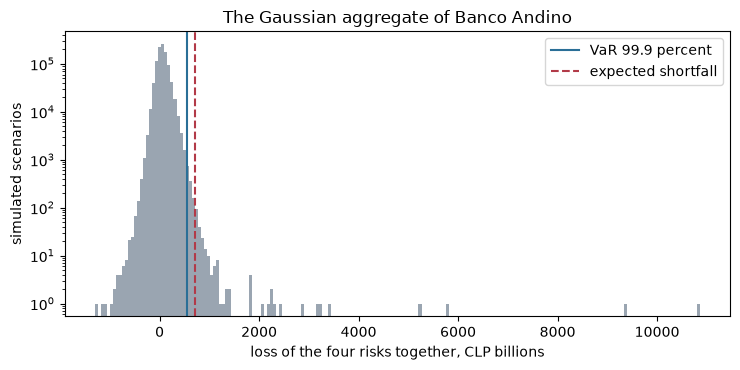

mean, VaR and ES of the total, CLP millions
66898.7 558727.5 709402.5
economic capital, VaR less expected loss 491998.8


In [4]:
# The VaR and expected shortfall of the total with the engine's estimators, and the histogram of the total
var_total = rv_port.var_from_sample(total, LEVEL)
es_total = rv_port.es_from_sample(total, LEVEL)
el_total = sum(m["el_clp_m"] for m in marginals)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.hist(total / 1e3, bins=200, color="#9aa5b1", log=True)
ax.axvline(var_total / 1e3, color="#2a6f97", label="VaR 99.9 percent")
ax.axvline(es_total / 1e3, color="#b23a48", linestyle="--", label="expected shortfall")
ax.set_xlabel("loss of the four risks together, CLP billions")
ax.set_ylabel("simulated scenarios")
ax.set_title("The Gaussian aggregate of Banco Andino")
ax.legend()
fig.tight_layout()
plt.show()
print("mean, VaR and ES of the total, CLP millions")
print(round(total.mean(), 1), round(var_total, 1), round(es_total, 1))
print("economic capital, VaR less expected loss", round(var_total - el_total, 1))

The mean of the total is CLP 66,899 million, which is its expected loss, and the 99.9 percent VaR is far to the right, at
CLP 558,727 million, with the expected shortfall further still: the tail is heavy, because operational risk and credit risk
carry long right tails. Subtracting the expected loss gives the economic capital of the Gaussian copula, the reference model
of this notebook. Everything below asks the same question of this one number, how much of it is the model.

## State of the art

The persisted research (dossiers 05 and 06) states the practice around each part of the case. The table puts it beside what the case does, with the source and the status of each statement.

| Part | The published practice | In the case and in the engine |
|---|---|---|
| **Supervisory stress-test models** | The Federal Reserve now publishes full model documentation (Fall 2026, credit risk models). Corporate expected loss is $PD \times LGD \times EAD$ per facility; the PD model is a set of 16 OLS regressions of vendor PD on the BBB spread and its four-quarter lag, estimated 2006 to 2023; LGD is stressed through the BBB spread, EAD through a loan-equivalent factor on Shared National Credit data; PPNR has its own 2026 model suite. | Five OLS satellites of charge-off rates by loan type on GDP growth and unemployment, fitted 1985 to 2019 (notebook 04): a simpler, different family. The Federal Reserve models **cannot be replicated to a published loss rate** from the public record, which is why case C19 stays planned (notebook 09). |
| **Bottom-up under constraints** | The EBA 2025 exercise is a constrained bottom-up stress test: banks use their own models under prescribed parameters, with a static balance sheet and benchmark parameters where no adequate satellite exists (Methodological Note, paragraphs 33 to 38 and 122 to 124). | The static rules by paragraph are applied and tested (notebook 05); the case has one bank and no challenger, so bottom-up against top-down is a rule shown, not a comparison made (notebook 07). |
| **Scenario generators** | Bayesian VARs with Minnesota priors (Litterman 1986; Banbura, Giannone and Reichlin 2010), global VARs, growth-at-risk with a skewed-t density (Adrian, Boyarchenko and Giannone 2019) and a panel quantile satellite (Covas, Rump and Zakrajsek 2014). | The engine has the VAR conditional forecast and the skewed-t step of growth-at-risk (notebook 04); the quantile-regression step needs `statsmodels`, absent from this environment; the Minnesota BVAR and the panel quantile satellite are deferred (backlog item BL-078). |
| **Risk aggregation** | Rosenberg and Schuermann (2006): total risk is more sensitive to the business mix than to the inter-risk correlations, the copula choice has a modest effect, and the additive approximation overestimates risk by about 30 to 40 percent. The Joint Forum found aggregation models "a work in progress" on which supervisors generally do not rely (the press release of 21 October 2010, https://www.bis.org/press/p101021.htm, gives both phrases). Vine copulas are available offline in `pyvinecopulib`. | The ladder from the simple sum to the worst case (notebooks 01 to 03), and the reference of Rosenberg and Schuermann read beside the result. The engine has Gaussian and t copulas and the closed forms of Clayton; **vine copulas are not in the engine** (BL-078) and `pyvinecopulib` is not in this environment. |
| **Model-risk quantification** | Barrieu and Scandolo (2015) and Glasserman and Xu (2014), as above; quantitative model-risk measures are sensitivity information, never a regulatory capital figure. | Both are in the engine and run in steps 1 and 2; the case labels them `information-not-capital`. |

The first two rows of the table concern models the case cannot run, the Federal Reserve's and the EBA's, and the third and the
fourth concern tools the engine lacks in part; the last row, model risk, is run in the two steps below, and the next cell then
measures what the committed documents let it measure.

### Measure 1: model risk over the set of aggregation models

The band of notebook 03 is a **set of models** for one quantity (the capital): the square-root rule, the Gaussian copula, three t copulas, and the two bounds. A single figure hides the spread among them, and the literature has measures of that spread (Barrieu and Scandolo, 2015). Let $\rho(X_0)$ be the measure under the **reference model**, and $\overline\rho$ and $\underline\rho$ its largest and smallest value over the set $\mathcal L$. Then

$$\mathrm{AM} = \frac{\overline\rho}{\rho(X_0)} - 1, \qquad \mathrm{RM} = \frac{\overline\rho - \rho(X_0)}{\overline\rho - \underline\rho} \in [0, 1].$$

The **add-on multiplier** AM generalises the Basel multiplier: multiplying the reference capital by $1 + \mathrm{AM}$ reaches the worst case in the set. The **relative measure** RM says where the reference sits between the best and worst case: 0 at the worst, 1 at the best. In the case the reference is the Gaussian copula and the set is the eight rows of the band, as sensitivity **information, not capital**.

The next cell calls `barrieu_scandolo` over the eight capitals of the band with the Gaussian copula as the reference and
offers it a reference index outside the set.

In [5]:
# Barrieu-Scandolo add-on multiplier and relative measure over the eight band rows
capitals = [row["capital_clp_m"] for row in band]
labels = [(row["method"], row["nu"]) for row in band]
reference = labels.index(("gaussian-copula", None))
measures = model_risk.barrieu_scandolo(capitals, reference)
committed_bs = agg["model_risk"]["barrieu_scandolo"]
print("reference capital, worst and best in the set")
print(round(measures.rho_x0, 1), round(measures.rho_max, 1), round(measures.rho_min, 1))
print("AM", round(measures.am, 6), "RM", round(measures.rm, 6))
print("committed AM and RM", round(committed_bs["am"], 6), round(committed_bs["rm"], 6))
print("reference times 1 + AM", round(measures.rho_x0 * (1 + measures.am), 1))
print("1 + AM and RM, percent", round(1 + measures.am, 2), round(measures.rm * 100))
try:
    model_risk.barrieu_scandolo(capitals, len(capitals))
except ValueError:
    print("a reference index outside the set is refused")

reference capital, worst and best in the set
491973.5 823331.5 118517.5
AM 0.673528 RM 0.470135
committed AM and RM 0.673528 0.470135
reference times 1 + AM 823331.5
1 + AM and RM, percent 1.67 47
a reference index outside the set is refused


The next cell draws the eight capitals as multiples of the Gaussian reference, with the range that the published additive
overestimate would give shaded.

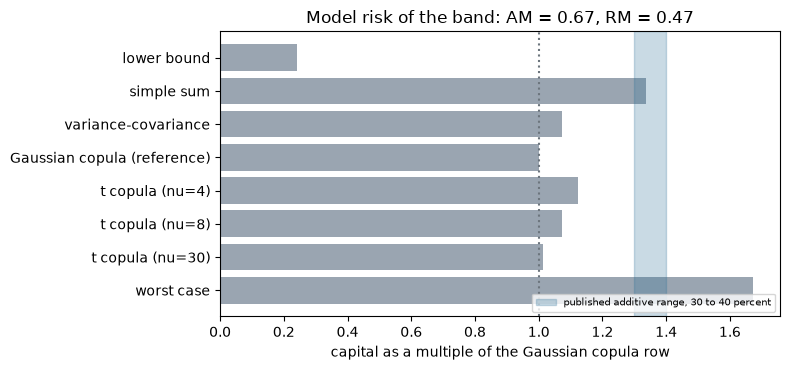

In [6]:
# The band as a multiple of the Gaussian reference, with the published additive range shaded
multiple = [c / measures.rho_x0 for c in capitals]
names = [NAMES[m] + (f" (nu={nu:g})" if nu else "") for m, nu in labels]
published = "published additive range, 30 to 40 percent"
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(names[::-1], multiple[::-1], color="#9aa5b1")
ax.axvspan(1.30, 1.40, color="#2a6f97", alpha=0.25, label=published)
ax.axvline(1.0, color="#6c757d", linestyle=":")
ax.set_xlabel("capital as a multiple of the Gaussian copula row")
ax.set_title(f"Model risk of the band: AM = {measures.am:.2f}, RM = {measures.rm:.2f}")
ax.legend(fontsize=7, loc="lower right")
fig.tight_layout()
plt.show()

The set of models is wide. The Gaussian reference is CLP 491,974 million and the eight rows run from 118,518 million, the
lower bound, to 823,332 million, the worst case, a ratio of 6.95. The add-on multiplier is 0.6735, so multiplying the reference
by 1.67 reaches the worst case, and the relative measure is 0.4701: the reference sits 47 percent of the way down from the worst
case to the best. The shaded band is what Rosenberg and Schuermann would expect for the simple sum over a diversified figure,
and the simple sum bar falls in it, but the spread of the set is far wider than the paper's range.

### Measure 2: the worst case within an entropy budget

Barrieu and Scandolo's set is the set of models the analyst wrote down. Glasserman and Xu (2014) ask a different question: **how wrong can the reference model be, in a measurable way, before a quantity changes by how much?** Take the baseline law of a loss $V$ (here the aggregate of the Gaussian copula) and consider every alternative law with likelihood ratio $m \ge 0$, $E[m] = 1$, whose **relative entropy** from the baseline is at most a budget $\eta$. The worst expected loss is

$$\sup_{m \ge 0,\ E[m\log m] \le \eta} E[m\,V], \qquad m_\theta = \frac{e^{\theta V}}{E[e^{\theta V}]},$$

with $\theta > 0$ chosen so that the entropy constraint binds: the worst case **tilts** the baseline sample towards its large losses, exponentially. It costs only a reweighting of the baseline simulation. `glasserman_xu_worst_case(v, budget)` returns the tilt $\theta$, the entropy reached, the baseline mean and the worst-case mean, and refuses a budget the sample cannot reach (the entropy of a tilt is at most $\log S$).

The case uses the budget $\eta = 0.05$ on the Gaussian aggregate.

The next cell runs `glasserman_xu_worst_case` on the simulated aggregate of step 1 for budgets from 0.005 to 0.25, prints four
of them and the refusal of an unreachable one.

In [7]:
# The Glasserman-Xu worst case within an entropy budget: a sweep of budgets, four of them printed, one refusal
budgets = np.linspace(0.005, 0.25, 25)
runs = [model_risk.glasserman_xu_worst_case(total, b) for b in budgets]
print("budget, tilt, entropy, baseline, worst case, ratio")
for budget in (0.01, 0.05, 0.1, 0.2):
    gx = model_risk.glasserman_xu_worst_case(total, budget)
    row = (budget, gx.theta, gx.relative_entropy, gx.baseline, gx.worst_case, gx.worst_case / gx.baseline)
    print("%5.2f %10.3e %7.4f %11.1f %11.1f %5.2f" % row)
committed_gx = agg["model_risk"]["glasserman_xu"]
print("committed, budget 0.05")
print(round(committed_gx["baseline_clp_m"], 1), round(committed_gx["worst_case_clp_m"], 1))
try:
    model_risk.glasserman_xu_worst_case(total[:50], 10.0)
except ValueError:
    print("a budget the sample cannot reach is refused")

budget, tilt, entropy, baseline, worst case, ratio
 0.01  6.367e-07  0.0100     66898.7     88454.2  1.32
 0.05  7.878e-07  0.0500     66898.7    143206.7  2.14
 0.10  8.497e-07  0.1000     66898.7    204035.3  3.05
 0.20  9.114e-07  0.2000     66898.7    317194.7  4.74
committed, budget 0.05
66898.5 143201.8
a budget the sample cannot reach is refused


The next cell draws the worst expected loss of the sweep as a multiple of the baseline, with the case's budget marked.

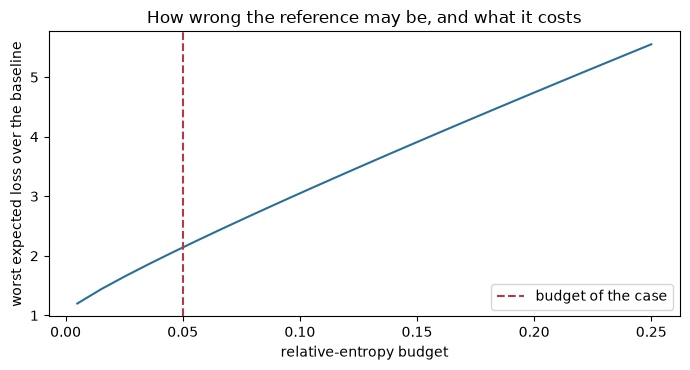

In [8]:
# The worst expected loss over the baseline as the entropy budget grows
ratio = [r.worst_case / r.baseline for r in runs]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(budgets, ratio, color="#2a6f97")
ax.axvline(0.05, color="#b23a48", linestyle="--", label="budget of the case")
ax.set_xlabel("relative-entropy budget")
ax.set_ylabel("worst expected loss over the baseline")
ax.set_title("How wrong the reference may be, and what it costs")
ax.legend()
fig.tight_layout()
plt.show()

The entropy budget turns a modelling doubt into a number. On the simulated aggregate, whose baseline mean is CLP 66,899
million, the worst expected loss within a budget of 0.01, 0.05, 0.10 and 0.20 is 88,454, 143,207, 204,035 and 317,195, which is
1.32, 2.14, 3.05 and 4.74 times the baseline. At the case's budget of 0.05 it matches the committed block, 143,202. The curve
is convex: the worst case grows faster than the budget because the aggregate is heavy-tailed, and the more tail the baseline
has, the more a given budget can move its mean. A budget the sample cannot reach, above log S of 3.91, is refused.

### Measuring the rest of the table

The next cell reads from the committed documents what each remaining row of the table can be measured on: the additive
overestimate against the published range of Rosenberg and Schuermann, the spread of the copula rows over the Gaussian one, the
business mix of the capital, and the back-cast peak ratios of the satellites that stand for the supervisory-model row.

In [9]:
# Measure on the committed documents what each remaining row of the table can be measured on
gaussian = next(r["capital_clp_m"] for r in band if r["method"] == "gaussian-copula")
simple_sum = agg["headline"]["capital_clp_m"]
reference_doc = read_json("C18/t-copula-baseline.json")["outputs"]["rosenberg_schuermann"]
overestimate = agg_tests.rosenberg_schuermann_reference(simple_sum, gaussian)
print("additive overestimate (engine)", round(overestimate.statistic, 4))
print("published range", reference_doc["published_additive_overestimate"])
copula_rows = [r["capital_clp_m"] for r in band if r["method"] in ("gaussian-copula", "t-copula")]
print("spread of the copula rows over the Gaussian row", round(max(copula_rows) / gaussian - 1, 4))
mix = {m["risk"]: round(m["ec_clp_m"] / simple_sum, 3) for m in marginals}
print("business mix, share of the simple sum", mix)
capitals_all = [r["capital_clp_m"] for r in band]
print("worst case over lower bound", round(max(capitals_all) / min(capitals_all), 2))
backcast = baseline_doc["outputs"]["backcast"]["per_loan_type"]
peaks = [round(b["metrics"]["peak_predicted"] / b["metrics"]["peak_realised"], 2) for b in backcast]
print("back-cast peak ratios", peaks)

additive overestimate (engine) 0.3376
published range {'low': 0.3, 'high': 0.4}
spread of the copula rows over the Gaussian row 0.1228
business mix, share of the simple sum {'credit': 0.396, 'market': 0.431, 'irrbb': 0.111, 'operational': 0.063}
worst case over lower bound 6.95
back-cast peak ratios [4.55, 13.14, 252.13, 4.3, 2.09]


## Results

The case sits inside the published practice on the points where it can be measured, and its distance to it is stated. The
additive overestimate of 0.3376 is inside the published 30 to 40 percent range, the t copula with four degrees of freedom is
12.3 percent above the Gaussian one, which is a larger copula effect than the paper's modest one, and the back-cast peak
ratios, 2.09 to 252.13, say that the stressed credit loss rests on satellites that fail their own validation (notebook 07).

**Answer:** one capital figure hides a great deal. The Gaussian reference of CLP 491,974 million is 47 percent of the way down
from the worst case of 823,332 million to the best of 118,518, the add-on multiplier is 0.6735 (the worst case is 1.67 times the
reference), and an entropy budget of 0.05 on the simulated aggregate lifts its expected loss from 66,899 to 143,207 million,
2.14 times, with 4.74 times at a budget of 0.20. What the case lacks is stated: the Federal Reserve models cannot be replicated
to a published loss rate from the public record, vine copulas and the Minnesota BVAR are not in the engine, and the first step of
growth-at-risk needs a package this environment lacks.

What this notebook does not show: the Glasserman-Xu figures are on an aggregate simulated from a grid of 1,961 points per
marginal, which agrees with the committed block to 0.01 percent and not to the digit; the table of the state of the art is the
research's, with its UNVERIFIED items marked, not a fresh literature review; and no number in it is a regulatory result.

## Summary

- The published practice has three layers: supervisory models (Federal Reserve, EBA), scenario generators (BVAR, GVAR, growth-at-risk, panel quantile) and aggregation (copulas, vines, the Joint Forum's caution); the case implements a simpler satellite family, the EBA static rules, a VAR and skewed-t mechanics, and the Gaussian, t and worst-case ladder.
- Model risk over the band is measured by the add-on multiplier and relative measure of Barrieu and Scandolo, which the engine recomputes exactly from the committed capitals, and by the Glasserman-Xu worst case within an entropy budget, which needs the simulated aggregate and tilts it towards its large losses.
- Both measures are sensitivity information for the validator, labelled `information-not-capital`, and say what one capital figure hides.
- What the engine does not have is stated, not hidden: vine copulas, the Minnesota BVAR, the panel quantile satellite and the first step of growth-at-risk (it needs `statsmodels`); the Federal Reserve models cannot be replicated to a published loss rate from the public record.

**What to try next.** Change the reference model of step 1 to the t copula with $\nu = 4$ and see how the add-on multiplier and relative measure move; then continue with notebook 09, which turns the band into a claim and reads the declared readiness of the case.

## References

- Glasserman, P. and Xu, X. (2014), Robust risk measurement and model risk, Quantitative Finance 14(1). https://doi.org/10.1080/14697688.2013.822989
- Barrieu, P. and Scandolo, G. (2015), Assessing financial model risk, European Journal of Operational Research 242(2). https://doi.org/10.1016/j.ejor.2014.10.032
- Rosenberg, J. V. and Schuermann, T. (2006), A general approach to integrated risk management with skewed, fat-tailed risks, Journal of Financial Economics 79(3). https://doi.org/10.1016/j.jfineco.2005.03.001
- Joint Forum (2010), Developments in modelling risk aggregation. https://www.bis.org/publ/joint25.pdf
- Bank for International Settlements (2010), press release of 21 October 2010 on the Joint Forum report Developments in modelling risk aggregation. https://www.bis.org/press/p101021.htm
- Board of Governors of the Federal Reserve System (2026), Supervisory Stress Test Model Documentation: Credit Risk Models, Fall 2026. https://www.federalreserve.gov/supervisionreg/files/fall-2026-credit-risk-models-description.pdf
- EBA (2025), 2025 EU-wide stress test, Methodological Note of 2025-01-20: the static balance sheet (paragraphs 24, 33, 34 and 90 to 92). https://www.eba.europa.eu/sites/default/files/2025-01/0246e2f3-fa57-47d1-99f2-7a5b80cae509/2025%20EU-wide%20stress%20test%20-%20Methodological%20Note.pdf
- Adrian, T., Boyarchenko, N. and Giannone, D. (2019), Vulnerable growth, American Economic Review 109(4). https://doi.org/10.1257/aer.20161923
- Litterman, R. B. (1986), Forecasting with Bayesian vector autoregressions: five years of experience, Journal of Business and Economic Statistics 4(1). https://doi.org/10.1080/07350015.1986.10509491
- Banbura, M., Giannone, D. and Reichlin, L. (2010), Large Bayesian vector auto regressions, Journal of Applied Econometrics 25(1). https://doi.org/10.1002/jae.1137
- Covas, F., Rump, B. and Zakrajsek, E. (2014), the panel quantile satellite, and Pesaran, Schuermann and Weiner (2004), the global VAR, as summarised in dossier 05, H.2 (no link: not read in this repository's research basis).
- This repository: `docs/contracts/engine/aggregation-api.md` (the model-risk functions).